# Case 2: Every column on the timeline: known before the call?
*Applies: Leakage and the prediction-time question · The column audit · Feature engineering
from the customer table (the 999 sentinel)*

Case 1 ended on a promise: the call-log join cuts the bill on 8,238 validation calls from
about Rs 2.80 lakh to about Rs 1.19 lakh. This notebook asks one question of every column
before that promise reaches the campaign head: on the morning the call list is made, do we
know this value for this client?

**Who needs the answer.** The campaign head, who would plan next month's calls on the
promise; the solution architect, who decides which feeds the scoring service may read; and
Kavya, who will ask the same question of Kalpa's payments feed.

**The questions on the way.** What does the call log know, and when is it written? Which
columns pass the prediction-time question? Do the economic columns carry the economy or the
calendar? How well does the model rank clients inside one month? What do `poutcome` and
`pdays` need? What is the honest score, and what did the leak promise in rupees? Where does
Kalpa hide the same leak?

**You will be able to** run the prediction-time question on every column, write the audit
table with a verdict and a reason per column, split a sentinel into a flag and a number, and
ship the honest score with its bill.

**Search terms:** data leakage in machine learning, target leakage, feature audit, leakage
checklist, train test contamination.

## What does the pipeline give us again?
The week's shared code, reloaded, plus today's scorer from case 1.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline every case notebook starts from: the same file, columns, split and baseline.
import io, zipfile, pathlib, urllib.request
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"  # verified 28 October 2026
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

# The customer table on the morning of the call: who the client is and how earlier campaigns went.
PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
# Joined on Wednesday from other feeds: the call log and the economic indicators.
CALL_LOG = ["duration"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

def logistic(columns, df):
    # pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
    num = [c for c in columns if pd.api.types.is_numeric_dtype(df[c])]
    cat = [c for c in columns if c not in num]
    prep = ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=2000))])

CALL_RS, MISSED_RS = 40, 1200            # Tuesday's costs: one call, one missed buyer's margin
THRESHOLD = CALL_RS / (CALL_RS + MISSED_RS)

def score(columns, tr=None, va=None):
    """Fit on training rows, score validation rows, and return the numbers the day quotes."""
    tr = train if tr is None else tr
    va = val if va is None else va
    ytr, yva = (tr["y"] == "yes").astype(int), (va["y"] == "yes").astype(int)
    model = logistic(columns, tr).fit(tr[columns], ytr)
    p = model.predict_proba(va[columns])[:, 1]
    tn, fp, fn, tp = confusion_matrix(yva, (p >= 0.5).astype(int)).ravel()
    tn2, fp2, fn2, tp2 = confusion_matrix(yva, (p >= THRESHOLD).astype(int)).ravel()
    top = yva.values[np.argsort(-p)[:1000]].sum()
    return {"columns": len(columns), "AUC": round(roc_auc_score(yva, p), 4),
            "accuracy": round(accuracy_score(yva, (p >= 0.5).astype(int)), 4),
            "TP": tp, "FP": fp, "FN": fn, "recall": round(tp / (tp + fn), 3),
            "bill_Rs": int(fp2 * CALL_RS + fn2 * MISSED_RS), "buyers_in_top_1000": int(top)}, model, p

bank = load_bank()
train, val, test = week_split(bank)
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)
print(f"{len(bank):,} calls: train {len(train):,}, validation {len(val):,}, "
      f"test {len(test):,} (sealed until Friday)")
print(f"Base rate: {y_train.mean():.2%} of training calls ended in a deposit")

41,188 calls: train 24,712, validation 8,238, test 8,238 (sealed until Friday)
Base rate: 11.27% of training calls ended in a deposit


## What does the call log know, and when is it written?
`duration` is the length of the last call in seconds. Split the calls into five equal groups
by length and look at how many in each group said yes.

**Predict before you run.** The shortest fifth of calls ends in a deposit (A) about 11
percent of the time, like everyone; (B) about 0.5 percent of the time; (C) about 33 percent
of the time.

In [2]:
fifths = pd.qcut(bank["duration"], 5)
by_length = bank.groupby(fifths, observed=True)["y"].apply(lambda s: (s == "yes").mean()).round(3)
print("yes-rate by call length, shortest fifth first:")
print(by_length.to_string())
zero = bank.loc[bank["duration"] == 0, "y"].value_counts()
print("\ncalls of 0 seconds and how they ended:", zero.to_dict())

yes-rate by call length, shortest fifth first:
duration
(-0.001, 89.0]     0.005
(89.0, 146.0]      0.032
(146.0, 222.0]     0.073
(222.0, 368.0]     0.125
(368.0, 4918.0]    0.330

calls of 0 seconds and how they ended: {'no': 4}


**What happened.** B. The shortest fifth converts at 0.5 percent and the longest at 33
percent, and every one of the four calls of zero seconds ended in no. A long call is often
the sale itself being made. The dataset's own documentation says the same about this
column: the length of a call strongly shapes the outcome, a call of zero seconds always
ends in no, nobody knows a call's length before dialling, and so the column belongs in
benchmarks and out of any model meant to make real predictions (UCI Bank Marketing page,
`duration` row of the variables table, verified 28 October 2026). The column is written
when the call ends, after the moment the list is made.

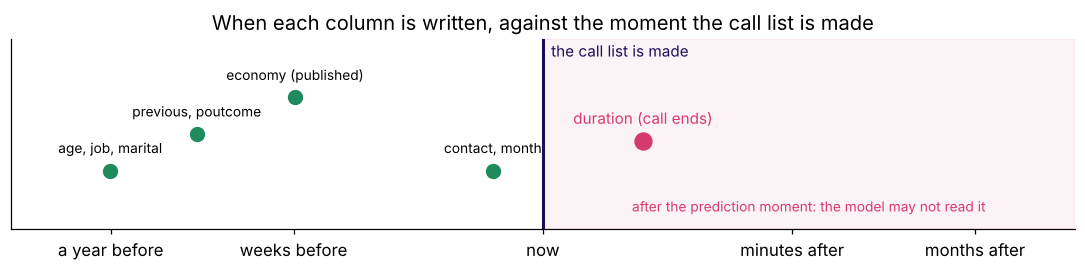

In [3]:
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.axvline(0, color=INK, lw=2)
ax.text(0.05, 1.18, "the call list is made", color=INK, fontsize=10)
known = {"age, job, marital": -400, "previous, poutcome": -120, "economy (published)": -30,
         "contact, month": -1}
later = {"duration (call ends)": 3}
for i, (name, t) in enumerate(known.items()):
    ax.plot(np.sign(t) * np.log10(abs(t) + 1), 0.4 + 0.25 * (i % 3), "o", color=GREEN, ms=9)
    ax.text(np.sign(t) * np.log10(abs(t) + 1), 0.52 + 0.25 * (i % 3), name, ha="center", fontsize=9)
for name, t in later.items():
    ax.plot(np.log10(t + 1), 0.6, "o", color=ROSE, ms=11)
    ax.text(np.log10(t + 1), 0.72, name, ha="center", fontsize=10, color=ROSE)
ax.axvspan(0, 3.2, color=ROSE, alpha=0.06)
ax.text(1.6, 0.12, "after the prediction moment: the model may not read it", ha="center", color=ROSE, fontsize=9)
ax.set_xlim(-3.2, 3.2); ax.set_ylim(0, 1.3); ax.set_yticks([])
ax.set_xticks([-2.6, -1.5, 0, 1.5, 2.6]); ax.set_xticklabels(["a year before", "weeks before", "now", "minutes after", "months after"])
ax.set_title("When each column is written, against the moment the call list is made")
plt.tight_layout(); plt.show()

## Which columns pass the prediction-time question?
The audit asks four things of every column: which system writes it, when it is written
against the moment the call list is made, whether it is known that morning, and the verdict
with its reason. The table below is the audit of all 20 input columns of the bank's file.

In [4]:
A = [  # column, written by, when it is written, known before the call, verdict, reason
 ("age, job, marital, education", "client file", "at account opening", "yes", "keep", "who the client is"),
 ("default, housing, loan", "credit file", "before the campaign", "yes", "keep", "the client's other products"),
 ("contact", "dialler", "when the call is planned", "yes", "keep", "the channel chosen for the call"),
 ("month, day_of_week", "dialler", "the day of the call", "yes", "keep, flag", "a calendar stamp; see the next section"),
 ("campaign", "dialler", "counts calls up to this one", "yes", "keep", "how often we have rung this campaign"),
 ("previous, poutcome", "campaign history", "when the last campaign closed", "yes", "keep", "how earlier campaigns went"),
 ("pdays", "campaign history", "when the last campaign closed", "yes", "engineer", "999 means never contacted"),
 ("duration", "call log", "when the call ends", "no", "drop", "written after the moment of prediction"),
 ("emp.var.rate, nr.employed", "research desk", "quarterly", "ask the owner", "keep, flag", "publication date not verified"),
 ("cons.price.idx, cons.conf.idx", "research desk", "monthly", "ask the owner", "keep, flag", "publication date not verified"),
 ("euribor3m", "research desk", "daily", "yes", "keep, flag", "moves with the other rates"),
]
audit = pd.DataFrame(A, columns=["columns", "written by", "written when", "known before the call",
                                 "verdict", "reason"])
audit

,columns,written by,written when,known before the call,verdict,reason
0,"age, job, marital, education",client file,at account opening,yes,keep,who the client is
1,"default, housing, loan",credit file,before the campaign,yes,keep,the client's other products
2,contact,dialler,when the call is planned,yes,keep,the channel chosen for the call
3,"month, day_of_week",dialler,the day of the call,yes,"keep, flag",a calendar stamp; see the next section
4,campaign,dialler,counts calls up to this one,yes,keep,how often we have rung this campaign
5,"previous, poutcome",campaign history,when the last campaign closed,yes,keep,how earlier campaigns went
6,pdays,campaign history,when the last campaign closed,yes,engineer,999 means never contacted
7,duration,call log,when the call ends,no,drop,written after the moment of prediction
8,"emp.var.rate, nr.employed",research desk,quarterly,ask the owner,"keep, flag",publication date not verified
9,"cons.price.idx, cons.conf.idx",research desk,monthly,ask the owner,"keep, flag",publication date not verified


**What happened.** One column fails outright: `duration`, written by the call log when the
call ends. Three sets carry a flag. The quarterly and monthly indicators pass only if each
figure was published before the call it sits beside, which is a question for the data owner
and is marked not verified here. The calendar columns pass the question and still need the
next section, because a column can be known that morning and still let the score borrow
from the split.

## Do the economic columns carry the economy, or the calendar?
The file runs in date order from May 2008 to November 2010, so the year can be rebuilt from
the order of the months. The economic columns take very few values, which is the first clue.

**Predict before you run.** A model given only the year and month of each call, and nothing
about the client, scores a validation AUC of (A) about 0.50, a coin; (B) about 0.65;
(C) about 0.79, close to the full honest model.

In [5]:
print("distinct values:", bank[ECONOMY].nunique().to_dict())
order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
m = bank["month"].map({x: i + 1 for i, x in enumerate(order)})
bank["year"] = 2008 + (m.diff().fillna(0) < 0).cumsum()
bank["year_month"] = bank["year"].astype(str) + "-" + m.astype(str).str.zfill(2)
train, val, test = week_split(bank)
print("yes-rate by year:", bank.groupby("year")["y"].apply(lambda s: round((s == "yes").mean(), 3)).to_dict())
calendar, _, _ = score(["year_month"])
print("AUC from year and month alone:", calendar["AUC"])

distinct values: {'emp.var.rate': 10, 'cons.price.idx': 26, 'cons.conf.idx': 26, 'euribor3m': 316, 'nr.employed': 11}


yes-rate by year: {2008: 0.048, 2009: 0.195, 2010: 0.521}
AUC from year and month alone: 0.7854


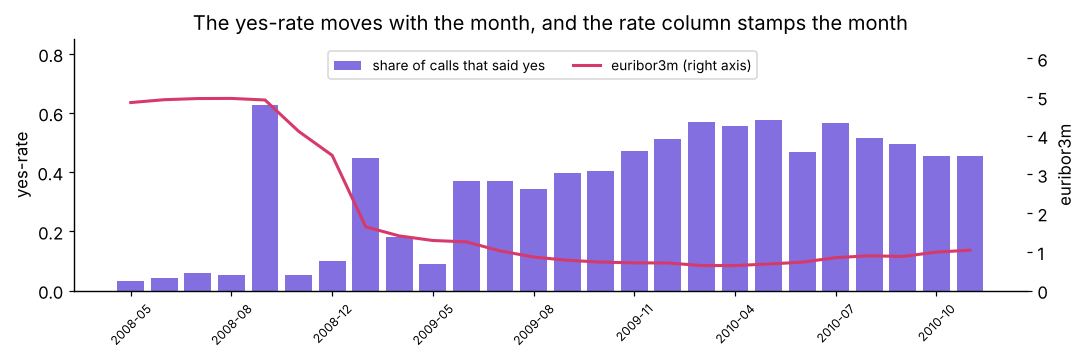

In [6]:
rate = bank.groupby("year_month")["y"].apply(lambda s: (s == "yes").mean())
eur = bank.groupby("year_month")["euribor3m"].mean()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(range(len(rate)), rate.values, color=VIOLET, alpha=0.75, label="share of calls that said yes")
ax2 = ax.twinx(); ax2.plot(range(len(eur)), eur.values, color=ROSE, lw=2, label="euribor3m (right axis)")
ax.set_xticks(range(0, len(rate), 3)); ax.set_xticklabels(rate.index[::3], rotation=45, fontsize=8)
ax.set_ylabel("yes-rate"); ax2.set_ylabel("euribor3m")
ax.set_title("The yes-rate moves with the month, and the rate column stamps the month")
ax.set_ylim(0, 0.85); ax2.set_ylim(0, 6.5)
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.86), ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

**What happened.** C. The year and month alone score about 0.79, against 0.795 for the
customer table plus the economy. The yes-rate runs from about 5 percent of calls in 2008 to
about 52 percent in 2010, and `emp.var.rate` and `nr.employed` take only 10 and 11 distinct
values, so they act as a stamp for the quarter. On a random split every month sits in both
training and validation, so the model is scored partly on months it has already seen. Next
month's call list is a month it has never seen.

## How well does the model rank clients inside one month?
The call centre ranks one month's list at a time, so the ranking that matters is the one
inside a month, where the calendar cannot help.

**Predict before you run.** Inside a single month the honest model's AUC is (A) about 0.80
as before; (B) about 0.57; (C) below 0.5.

In [7]:
bank = bank.assign(never_contacted=(bank["pdays"] == 999).astype(int),
                   days_since_contact=bank["pdays"].where(bank["pdays"] != 999, 0))
train, val, test = week_split(bank)
HONEST = PROFILE + HISTORY + ["never_contacted", "days_since_contact"] + ECONOMY
honest, honest_model, p_honest = score(HONEST)
v = val.assign(p=p_honest, yes=(val["y"] == "yes").astype(int))
rows = [(k, len(g), roc_auc_score(g["yes"], g["p"])) for k, g in v.groupby("year_month")
        if len(g) >= 100 and g["yes"].nunique() == 2]
inside = pd.DataFrame(rows, columns=["month", "validation calls", "AUC inside the month"]).round(3)
within = float(np.average(inside["AUC inside the month"], weights=inside["validation calls"]))
print(f"overall validation AUC {honest['AUC']}, weighted AUC inside one month {within:.3f}")
inside

overall validation AUC 0.7955, weighted AUC inside one month 0.568


,month,validation calls,AUC inside the month
0,2008-05,1549,0.578
1,2008-06,847,0.573
2,2008-07,1341,0.552
3,2008-08,1018,0.500
4,2008-11,744,0.522
5,2009-04,506,0.667
6,2009-05,1154,0.610
7,2009-06,162,0.592
8,2009-08,144,0.603


**What happened.** B. Inside one month the honest model ranks clients at about 0.57; most
of the gap up to 0.80 is the model knowing which month a call was made in. The calendar
columns are a second leak that looks legal: each value is known on the morning of the call,
and the random split still lets the score borrow each month's yes-rate from training rows of
the same month. The verdict is keep and flag: they stay in Wednesday's feature set with this
caveat written beside the score, and Friday's split by time puts a price on it.

## What do poutcome and pdays need?
Two columns look suspicious for opposite reasons. `poutcome = success` sounds too good, and
`pdays` sounds like a plain number of days.

**Predict before you run.** Clients whose previous campaign ended in success say yes this
time (A) about 11 percent of the time; (B) about 65 percent of the time, which makes the
column a leak; (C) about 65 percent of the time, and the column stays.

In [8]:
print(bank.groupby("poutcome")["y"].apply(lambda s: round((s == "yes").mean(), 3)).to_dict())
never = (bank["pdays"] == 999).mean()
print(f"pdays == 999 in {never:.2%} of rows; mean of raw pdays: {bank['pdays'].mean():.0f} days")
print("contacted before, days since contact:", bank.loc[bank["pdays"] != 999, "pdays"].describe()[["min", "50%", "max"]].to_dict())
raw, _, _ = score(PROFILE + HISTORY + ["pdays"] + ECONOMY)
print("AUC with raw pdays:", raw["AUC"], "| with the flag and the days:", honest["AUC"])

{'failure': 0.142, 'nonexistent': 0.088, 'success': 0.651}
pdays == 999 in 96.32% of rows; mean of raw pdays: 962 days
contacted before, days since contact: {'min': 0.0, '50%': 6.0, 'max': 27.0}


AUC with raw pdays: 0.7951 | with the flag and the days: 0.7955


**What happened.** C. A previous success converts at 65 percent, and the column stays,
because the previous campaign closed months before this call: it passes the prediction-time
question. "Too good" is a reason to ask the question and never the verdict. `pdays` holds
999 for 96.3 percent of rows, which means never contacted, so its raw mean of about 962 days
describes nobody. The fix is two columns: `never_contacted` (1 when pdays is 999) and
`days_since_contact` (the days for the 3.7 percent who were contacted, 0 otherwise). The
AUC barely moves on this file; the model now reads a sentence a person can say aloud.

## What is the honest score, and what did the leak promise in rupees?
The audited set is the customer table, the two engineered `pdays` columns and the economy,
with `duration` dropped. Score it beside the leaked set.

**Predict before you run.** The honest bill on 8,238 validation calls is (A) about the leaked
Rs 1.19 lakh; (B) about Rs 2.8 lakh; (C) higher than calling everyone.

In [9]:
leaked, _, _ = score(PROFILE + HISTORY + ["never_contacted", "days_since_contact"] + ECONOMY + CALL_LOG)
everyone = int(len(val) - y_val.sum()) * CALL_RS
final = pd.DataFrame({"leaked (with duration)": leaked, "honest (audited)": honest}).T[
    ["columns", "AUC", "accuracy", "recall", "bill_Rs", "buyers_in_top_1000"]]
print(f"calling all 8,238 validation clients costs Rs {everyone/1e5:.2f} lakh in calls and misses nobody")
final

calling all 8,238 validation clients costs Rs 2.92 lakh in calls and misses nobody


,columns,AUC,accuracy,recall,bill_Rs,buyers_in_top_1000
leaked (with duration),21.0,0.9327,0.9076,0.421,118520.0,574.0
honest (audited),20.0,0.7955,0.8991,0.231,281680.0,462.0


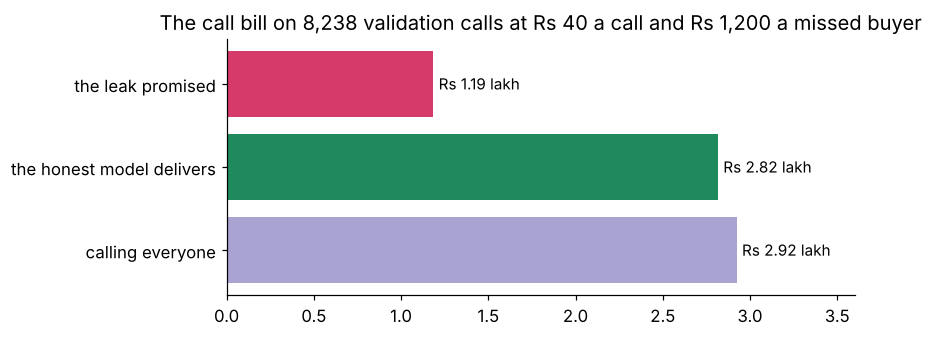

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ["the leak promised", "the honest model delivers", "calling everyone"]
values = [leaked["bill_Rs"] / 1e5, honest["bill_Rs"] / 1e5, everyone / 1e5]
ax.barh(labels, values, color=[ROSE, GREEN, GREY])
for i, x in enumerate(values):
    ax.text(x + 0.03, i, f"Rs {x:.2f} lakh", va="center", fontsize=10)
ax.invert_yaxis(); ax.set_xlim(0, 3.6)
ax.set_title("The call bill on 8,238 validation calls at Rs 40 a call and Rs 1,200 a missed buyer")
plt.tight_layout(); plt.show()

**What happened.** B. The honest model scores AUC 0.796 with recall 0.23 at 0.5, and its
bill is about Rs 2.82 lakh against the Rs 1.19 lakh the leak promised. The leaked model could
never deliver its promise, because on the morning of the call the column it leans on does
not exist yet. The score fell and the model got better: the honest one can run. At these
costs the honest bill sits close to calling everyone (about Rs 2.92 lakh), which is
Tuesday's lesson: a cheap call makes the threshold call almost everyone, and the model earns
its keep under a budget, where its top 1,000 hold 462 buyers against 113 for a random 1,000.

## Where does Kalpa hide the same leak?
Kalpa's junior found `settlement_status` in the payments feed and lifted validation to 0.99.
The data platform lead, reading the schema, said the field is written after delivery, when
the payment clears. The nudge goes out on a morning before any order exists, so a settled
payment can only appear for a member who has already bought: the column is the target,
written by another system in another vocabulary. It fails the prediction-time question the
way `duration` does, and the audit row says so.

In [11]:
kalpa = pd.DataFrame([
    ("orders_90d", "orders table", "nightly, before the nudge", "yes", "keep"),
    ("days_since_last_order", "orders table", "nightly, before the nudge", "yes", "keep"),
    ("settlement_status", "payments feed", "after delivery, when the payment clears", "no", "drop"),
], columns=["column", "written by", "written when", "known on the nudge morning", "verdict"])
kalpa

,column,written by,written when,known on the nudge morning,verdict
0,orders_90d,orders table,"nightly, before the nudge",yes,keep
1,days_since_last_order,orders table,"nightly, before the nudge",yes,keep
2,settlement_status,payments feed,"after delivery, when the payment clears",no,drop


In [12]:
check("the four calls of 0 seconds all ended in no", zero.to_dict() == {"no": 4})
check("duration is the only column dropped by the audit", list(audit.loc[audit["verdict"] == "drop", "columns"]) == ["duration"])
check("the calendar alone scores above 0.75", calendar["AUC"] > 0.75)
check("inside one month the honest model ranks below 0.65", within < 0.65)
check("the honest model scores more than 0.12 AUC below the leaked one", leaked["AUC"] - honest["AUC"] > 0.12)
check("the leak promised a bill at least Rs 1 lakh lower", honest["bill_Rs"] - leaked["bill_Rs"] > 100000)

PASS  the four calls of 0 seconds all ended in no
PASS  duration is the only column dropped by the audit
PASS  the calendar alone scores above 0.75
PASS  inside one month the honest model ranks below 0.65
PASS  the honest model scores more than 0.12 AUC below the leaked one
PASS  the leak promised a bill at least Rs 1 lakh lower


## What does case 2 hand to case 3?
| Question | Answer from this notebook |
|---|---|
| When is `duration` written? | When the call ends, after the list is made, so it is dropped |
| Do the economic columns pass? | They pass the question and act as a calendar on a random split: keep, flag, Friday prices it |
| What does `poutcome = success` get? | Kept: 65 percent yes, and known months before the call |
| What does `pdays` need? | A never-contacted flag plus the days, since 999 is a sentinel |
| The honest score | AUC 0.796, about 0.57 inside one month, bill about Rs 2.82 lakh |
| What the leak promised | AUC 0.93 and a bill about Rs 1.6 lakh lower, which no live list could deliver |

Case 3 reads the honest model's coefficients and its importance chart and asks what they can
and cannot prove.